# Direct-Indirect parameter exploration (high resolution)

In [1]:
import sys
from pathlib import Path


root_path = Path.cwd().parent
if str(root_path) not in sys.path:
    sys.path.append(str(root_path))

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="ticks", palette="Set2")
import pandas as pd
import glob
import os
import numpy as np
from simulation_neurog import CellSimulation
import itertools
from tqdm import tqdm
import matplotlib.path as mpath
import matplotlib.patches as mpatches

layers_gaus_coef = pd.read_csv(Path.cwd().parent / 'supplementary' / 'layers_gaus_coef.csv')
layers_density = pd.read_csv(Path.cwd().parent / 'supplementary' / 'layers_percent.csv')

def plot_function(f, title = ''):
    x_line = np.linspace(0, 8, 100)
    y_line = f(x_line)

    plt.plot(x_line, y_line)
    plt.ylim([0,1])
    plt.grid()
    plt.title(title)
    plt.show()


def create_sigmoid(k, x0, start, end):
    return lambda x: 1/(1 + np.exp(-k*(x - x0)))*(end - start) + start


def centered_range(start, end, n_steps):
    return np.linspace(start, end, n_steps)

# layer colors
layer_colors = {'l6': '#a400fe',
                'l5': '#e33e00',
                'l4': '#ffc000',
                'l23': '#0088ab'}
layers = layer_colors.keys()
colors = [layer_colors.get(layer, '#333333') for layer in layers]

c_light = '#bbbbbb'
c_th = '#ff00ff'

neuro_colors = ['#1c9d40', '#c21745', '#23a3ae', '#e46b0f', '#666666', "#ff7499"]
neuro_labels = ['apical P', 'basal P', 'apical N', 'basal N']
neuro_colors_dict = dict(zip(neuro_labels, neuro_colors))

color_200_15 = "#038803"
color_200_not15 = "#a7e2a7"

## calculation of parameter combinations

slow exploration of possible parameter ranges

In [2]:
# range_k_A_N = centered_range(0.5, 2, 4)
# range_x0_A_N = centered_range(2, 6, 3)
# range_start_A_N = centered_range(0, 0.5, 6)
# range_end_A_N = centered_range(0, 0.6, 7)

# range_k_B_N = centered_range(0.5, 2, 4)
# range_x0_B_N = centered_range(2, 6, 3)
# range_start_B_N = centered_range(0, 1, 6)
# range_end_B_N = centered_range(1, 1, 1)


# arrays = [range_k_A_N, range_x0_A_N, range_start_A_N, range_end_A_N, range_k_B_N, range_x0_B_N, range_start_B_N, range_end_B_N]
# param_names = ['k_A_N', 'x0_A_N', 'start_A_N', 'end_A_N', 'k_B_N', 'x0_B_N', 'start_B_N', 'end_B_N']

# rows = []

# combinations = list(itertools.product(*arrays))

# len_combos = len(combinations)


# a0_perc = 0.866

# for i, combo in enumerate(tqdm(combinations)):
#     # print(f'{i} / {len_combos}')
#     row = dict(zip(param_names, combo))

#     pA_to_N_fc_test = create_sigmoid(combo[0], combo[1], combo[2], combo[3])

#     pB_to_N_fc_test = create_sigmoid(combo[4], combo[5], combo[6], 1)


#     test = CellSimulation(
#                 n_aP0=a0_perc, n_bP0=1-a0_perc,

#                 layers_dist=layers_gaus_coef,
#                 layers_perc=layers_density,

#                 min_per_frame=360,

#                 pA_to_N_fc = pA_to_N_fc_test,
#                 perc_A_fc = lambda x: -0.0330568898* x + 0.8658511766,

#                 pB_to_N_fc = pB_to_N_fc_test,
#                 force_p = True,
#                 disable_bars=True
#                 )

#     test.run()

#     days = test.get_tables()['days']
#     n_cells = test.get_tables()['n_cells']
#     n_prog = np.sum(n_cells[0:2], axis = 0)
#     n_neur = np.sum(n_cells[2:], axis = 0)

#     row['a_prog_17'] = n_cells[0, days >= 17][0]
#     row['b_prog_17'] = n_cells[1, days >= 17][0]
#     row['prog_17'] = n_prog[days >= 17][0]

#     row['a_neur_17'] = n_cells[2, days >= 17][0]
#     row['b_neur_17'] = n_cells[3, days >= 17][0]
#     row['neur_17'] = n_neur[days >= 17][0]

#     new_neur = test.get_tables()['new_cells'][2:]
#     perc_A = new_neur[0] / np.sum(new_neur, axis = 0)

#     row['perc_D_11'] = perc_A[0]
#     row['perc_D_17'] = perc_A[days >= 17][0]

#     rows.append(row)

## reading of parameter combinations

36288


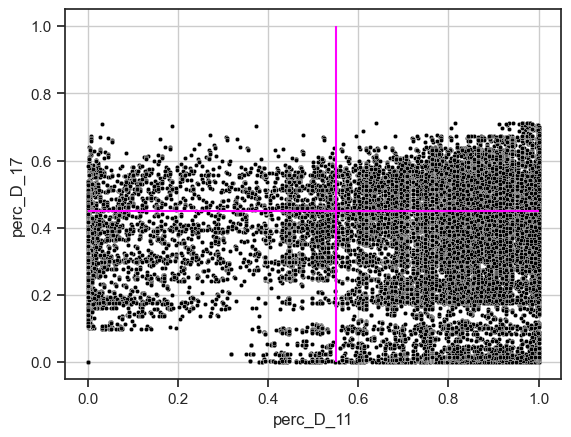

In [3]:
df = pd.read_csv(Path.cwd().parent / 'supplementary' / 'direct_indirect_exploration_higher-res.csv')

len_0 = len(df)
print(len_0)

sns.scatterplot(data = df, x = 'perc_D_11', y = 'perc_D_17', s = 10, color = 'black')
plt.grid()

plt.vlines(x = 0.55, ymin = 0, ymax = 1, color = c_th)
plt.hlines(y = 0.45, xmin = 0, xmax = 1, color = c_th)


(0.0, 1.0)

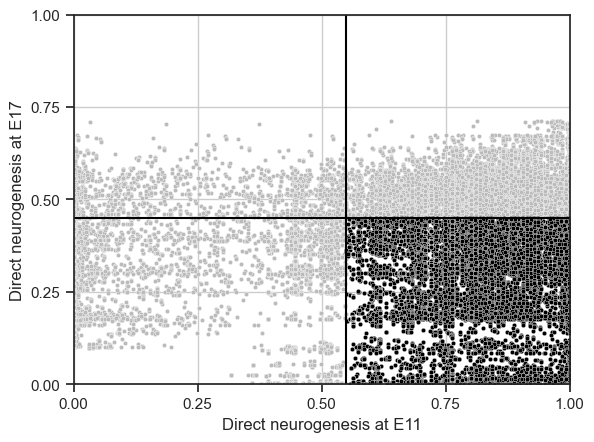

In [4]:
sns.scatterplot(data = df, x = 'perc_D_11', y = 'perc_D_17', s = 10, color = c_light)
sns.scatterplot(data = df[(df['perc_D_11'] > 0.55) & (df['perc_D_17'] < 0.45)], x = 'perc_D_11', y = 'perc_D_17', s = 10, color = 'black')
plt.grid()
plt.xlabel('Direct neurogenesis at E11')
plt.ylabel('Direct neurogenesis at E17')

plt.vlines(x = 0.55, ymin = 0, ymax = 1, color = '#000000')
plt.hlines(y = 0.45, xmin = 0, xmax = 1, color = '#000000')

tick_size = 0.25
plt.xticks(np.arange(0,1+tick_size,tick_size))
plt.yticks(np.arange(0,1+tick_size,tick_size))

plt.xlim(0,1)
plt.ylim(0,1)

In [5]:
df_D_I = df[(df['perc_D_11'] > 0.55) & (df['perc_D_17'] < 0.45)]
print(len(df_D_I))

15917


Text(0, 0.5, 'neurons at E17')

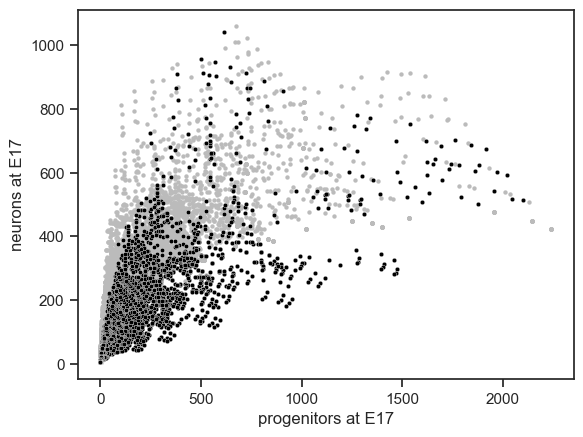

In [6]:
sns.scatterplot(data = df, x = 'prog_17', y = 'neur_17', s = 10, color = c_light, linewidth=0)
sns.scatterplot(data = df_D_I, x = 'prog_17', y = 'neur_17', s = 10, color = 'black')
# plt.grid()
plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')


2569


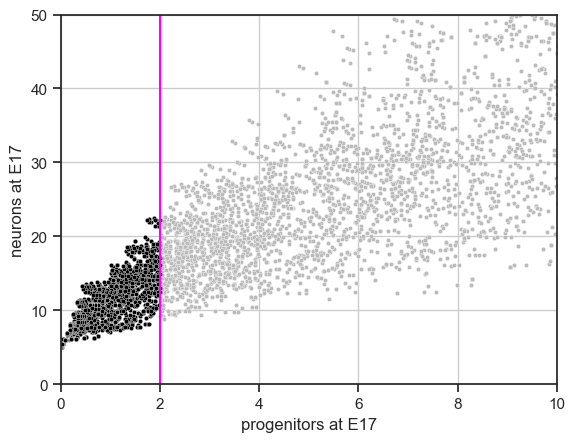

In [7]:
prog_th = 2

sns.scatterplot(data = df_D_I, x = 'prog_17', y = 'neur_17', s = 10, color = c_light)
sns.scatterplot(data = df_D_I[df_D_I['prog_17'] < prog_th], x = 'prog_17', y = 'neur_17', s = 10, color = 'black')
plt.grid()
plt.xlim([0,10])
plt.ylim([0,50])
plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')


plt.vlines(x = prog_th, ymin = 0, ymax = 100, color = c_th)

subset0_df = df_D_I[df_D_I['prog_17'] < prog_th]

print(len(subset0_df))

In [8]:
color_200 = '#22bb22'

232


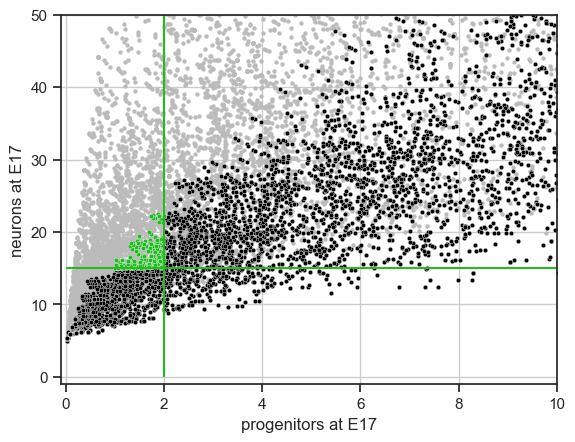

In [9]:
neur_th = 15

sns.scatterplot(data = df, x = 'prog_17', y = 'neur_17', s = 10, color = c_light, linewidth=0)
sns.scatterplot(data = df_D_I, x = 'prog_17', y = 'neur_17', s = 10, color = 'black')

sns.scatterplot(data = subset0_df[subset0_df['neur_17'] > neur_th], x = 'prog_17', y = 'neur_17', s = 10, color = '#22bb22')
plt.grid()
plt.xlim([-0.1,10])
plt.ylim([-1,50])
plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')



plt.vlines(x = prog_th, ymin = 0, ymax = 100, color = color_200)
plt.hlines(y = neur_th, xmin = 0, xmax = 100, color = color_200)

subset_df = subset0_df[subset0_df['neur_17'] > neur_th]


print(len(subset_df))
n_sim = len(subset_df)


(-20.0, 1040.4914357357554)

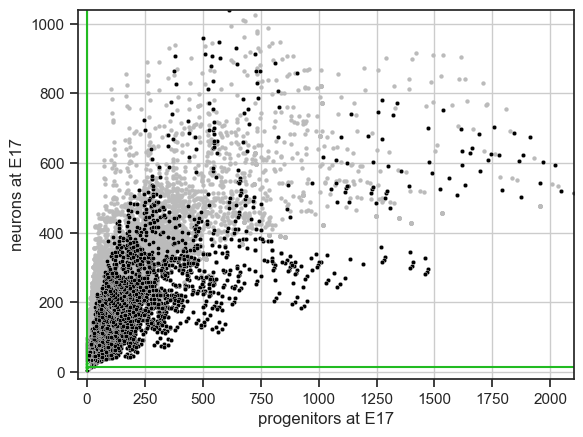

In [10]:
sns.scatterplot(data = df, x = 'prog_17', y = 'neur_17', s = 10, color = c_light, linewidth=0)
sns.scatterplot(data = df_D_I, x = 'prog_17', y = 'neur_17', s = 10, color = 'black')
sns.scatterplot(data = subset0_df[subset0_df['neur_17'] > neur_th], x = 'prog_17', y = 'neur_17', s = 10, color = '#22bb22')
plt.grid()
plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')

plt.vlines(x = prog_th, ymin = 0, ymax = df_D_I['neur_17'].max(), color = color_200)
plt.hlines(y = neur_th, xmin = 0, xmax = df_D_I['prog_17'].max(), color = color_200)

plt.xlim(-40, df_D_I['prog_17'].max())
plt.ylim(-20, df_D_I['neur_17'].max())

# plt.gca().add_patch(plt.Rectangle((-0.1, -1), 10.1, 50, fill=False, color="#88cfff"))


In [11]:
subset_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / '00test_from-36k.csv')

(0.0, 100.0)

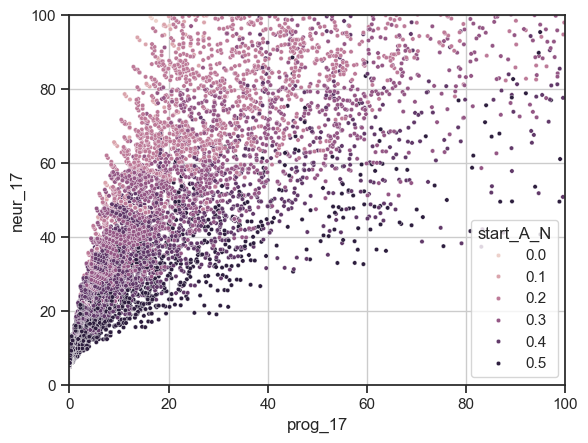

In [12]:
# df_D_I['direct_ratio'] = df_D_I['direct_ratio']

sns.scatterplot(data = df_D_I, x = 'prog_17', y = 'neur_17', hue = 'start_A_N', s = 10)
plt.grid()
plt.xlim([0,100])
plt.ylim([0,100])

## fine calculation of subset

In [13]:
# a0_perc = 0.866

# sim_list = []

# for i, row in tqdm(subset_df.iterrows(), total=len(subset_df)):
#     params_A_N = row.iloc[:4]
#     params_B_N = row.iloc[4:8]


#     pA_to_N_fc = create_sigmoid(*params_A_N)
#     pB_to_N_fc = create_sigmoid(*params_B_N)


#     current_sim = CellSimulation(
#                 n_aP0=a0_perc, n_bP0=1-a0_perc,

#                 layers_dist=layers_gaus_coef,
#                 layers_perc=layers_density,

#                 min_per_frame=60,

#                 pA_to_N_fc = pA_to_N_fc,
#                 perc_A_fc = lambda x: -0.0330568898* x + 0.8658511766,

#                 pB_to_N_fc = pB_to_N_fc,
#                 force_p = True,
#                 disable_bars=True
#                 )

#     current_sim.run()

#     sim_list.append(current_sim)

In [14]:
# def binary_search(a, start = 0, end = -1):
#     # looking for when a value changes sign
#     if end == -1:
#         end = len(a)-1

#     middle = start + (end-start)//2

#     if end-start > 1:
#         if a[start] * a[middle] < 0:
#             return binary_search(a, start, middle)
#         else:
#             return binary_search(a, middle, end)
#     else:
#         return middle

# days = sim_list[0].get_tables()['days']
# neurogenesis_list = []
# E_list = []
# metric_list = []
# crossing_list = []

# for s in sim_list:
#     new_neurons = s.get_tables()['new_cells'][2:]
#     a_neurogenesis = new_neurons[0] / np.sum(new_neurons, axis = 0)
#     neurogenesis_list.append(a_neurogenesis)

#     crossing_list.append(days[binary_search(a_neurogenesis-0.5)])

#     E_list.append(s.get_tables()['probs'][5])

#     metric_list.append(s.get_metrics(age=17))

In [15]:
# subset_df['crossing'] = crossing_list
# subset_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_readout.csv')

# neurogenesis_df = pd.DataFrame(neurogenesis_list, index = subset_df.index)
# neurogenesis_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_direct.csv')

# E_df = pd.DataFrame(E_list, index = subset_df.index)
# E_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_E.csv')

# metric_df = pd.DataFrame(metric_list, index = subset_df.index)
# metric_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_metrics.csv')

# days_df = pd.DataFrame(days)
# days_df.to_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'days.csv', index=False)


## reading data from csv

In [16]:
subset_df = pd.read_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_readout.csv', index_col=0)

neurogenesis_df = pd.read_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_direct.csv', index_col=0)

E_df = pd.read_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_E.csv', index_col=0)

metric_df = pd.read_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'combination_subsets_metrics.csv', index_col=0)

days = pd.read_csv(Path.cwd().parent / 'supplementary' / 'big_exploration' / 'days.csv').values[:,0]

n_sim = len(subset_df)

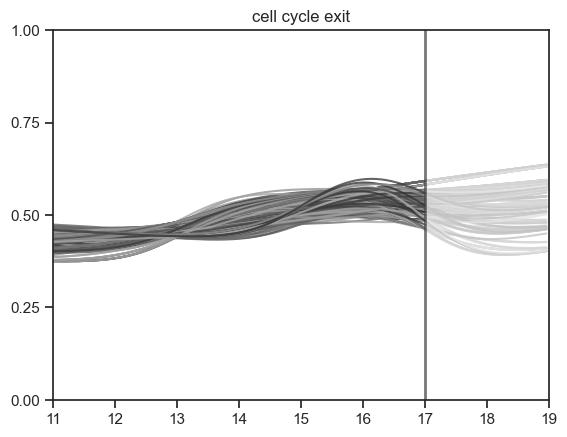

In [17]:
e_color = '#333333'

e_starting_c = 125
e_color_def = 300

e_colors = sns.light_palette(e_color, n_colors = max(e_color_def, e_starting_c+n_sim))

e_colors = e_colors[e_starting_c:e_starting_c+n_sim]
e_colors = np.array(e_colors)


perm = np.random.permutation(len(e_colors))

e_colors = e_colors[perm]


for i, (idx, y) in enumerate(E_df.iterrows()):
    plt.plot(days, y, color = e_colors[i], alpha = 0.8)

plt.title('cell cycle exit')
# plt.grid()
# plt.hlines(0.5, xmin=11, xmax=19, color = "#bbbbbb", zorder=1)
plt.xlim([11,19])
plt.ylim([0,1])

plt.yticks(np.arange(0,1.25,0.25))

plt.gca().add_patch(plt.Rectangle((17, -0.1),
                                  2.2, 1.3,
                                  facecolor="#ffffff",
                                  alpha=0.7,
                                  edgecolor="#3d3d3d",
                                  linewidth=2,
                                  zorder = 2))

(0.0, 1.0)

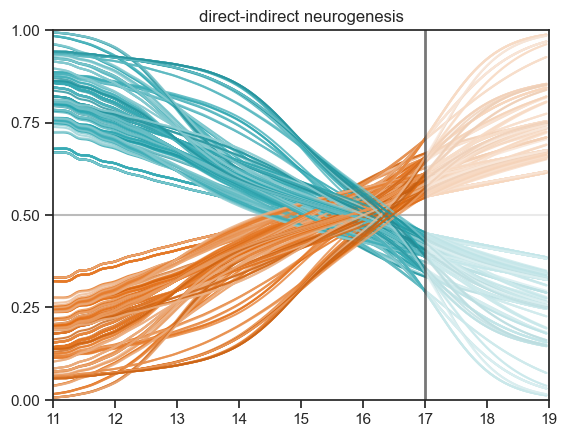

In [18]:
a_color = '#23a3ae'
b_color = '#e46b0f'

starting_c = 125
color_def = 300


a_colors_l = sns.light_palette(a_color, n_colors = color_def)
a_colors_d = sns.dark_palette(a_color, n_colors = color_def, reverse=True)

a_colors = a_colors_l + a_colors_d
a_colors = a_colors[starting_c:starting_c+n_sim]
a_colors = np.array(a_colors)

b_colors_l = sns.light_palette(b_color, n_colors = color_def)
b_colors_d = sns.dark_palette(b_color, n_colors = color_def, reverse=True)

b_colors = b_colors_l + b_colors_d
b_colors = b_colors[starting_c:starting_c+n_sim]
b_colors = np.array(b_colors)


a_colors = a_colors[perm]
b_colors = b_colors[perm]

for i, (idx, y) in enumerate(neurogenesis_df.iterrows()):
    plt.plot(days, y, color = a_colors[i], alpha = 0.8)
    plt.plot(days, 1-y, color = b_colors[i], alpha = 0.8)

plt.title('direct-indirect neurogenesis')

plt.hlines(0.5, xmin=11, xmax=19, color = "#bbbbbb", zorder=1)

plt.gca().add_patch(plt.Rectangle((17, -0.1),
                                  2.2, 1.2,
                                  facecolor="#ffffff",
                                  alpha=0.7,
                                  edgecolor="#3d3d3d",
                                  linewidth=2,
                                  zorder = 2))

plt.yticks(np.arange(0,1.25,0.25))

# plt.grid()
plt.xlim([11,19])
plt.ylim([0,1])


In [19]:
subset_df

,k_A_N,x0_A_N,start_A_N,end_A_N,k_B_N,x0_B_N,start_B_N,end_B_N,a_prog_17,b_prog_17,prog_17,a_neur_17,b_neur_17,neur_17,perc_D_11,perc_D_17,crossing
1805,0.5,2.0,0.3,0.4,0.5,2.0,1.0,1.0,0.754948,0.383089,1.138037,9.112123,7.011206,16.123329,0.679556,0.448813,15.541667
1811,0.5,2.0,0.3,0.4,0.5,4.0,1.0,1.0,0.754948,0.383089,1.138037,9.112123,7.011206,16.123329,0.679556,0.448813,15.541667
1817,0.5,2.0,0.3,0.4,0.5,6.0,1.0,1.0,0.754948,0.383089,1.138037,9.112123,7.011206,16.123329,0.679556,0.448813,15.541667
1823,0.5,2.0,0.3,0.4,1.0,2.0,1.0,1.0,0.754948,0.383089,1.138037,9.112123,7.011206,16.123329,0.679556,0.448813,15.541667
1829,0.5,2.0,0.3,0.4,1.0,4.0,1.0,1.0,0.754948,0.383089,1.138037,9.112123,7.011206,16.123329,0.679556,0.448813,15.541667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35845,2.0,6.0,0.5,0.0,2.0,4.0,0.2,1.0,1.003469,0.509197,1.512665,12.121539,3.771639,15.893178,0.941619,0.317522,16.250000
35899,2.0,6.0,0.5,0.1,1.5,4.0,0.2,1.0,0.920262,0.466975,1.387237,11.919464,3.611758,15.531222,0.941059,0.373639,16.416667
35917,2.0,6.0,0.5,0.1,2.0,4.0,0.2,1.0,0.918667,0.466166,1.384833,12.220851,3.734383,15.955234,0.941619,0.368745,16.333333
35971,2.0,6.0,0.5,0.2,1.5,4.0,0.2,1.0,0.840999,0.426754,1.267752,12.010838,3.577634,15.588471,0.941059,0.417815,16.541667


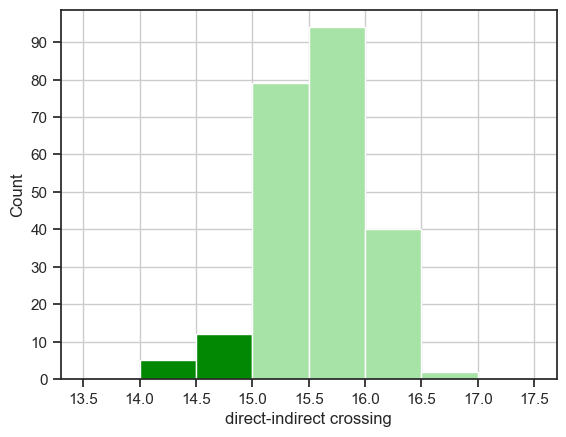

In [20]:
ax = sns.histplot(subset_df['crossing'], bins = centered_range(13.5, 17.5, 9), color = '#666666', alpha = 1)
plt.yticks(np.arange(0, 100, 10))
plt.grid()
plt.xlabel('direct-indirect crossing')

for patch, color in zip(ax.patches, [*[color_200_15]*3, *[color_200_not15]*5]):
    patch.set_facecolor(color)


In [21]:
set(subset_df[subset_df['crossing'] <= 15].index)

{2236,
 2254,
 2272,
 2290,
 8158,
 8176,
 8194,
 8265,
 11326,
 11344,
 11362,
 11846,
 11864,
 20398,
 20416,
 20434,
 29470,
 29488,
 29506}

(0.0, 1.0)

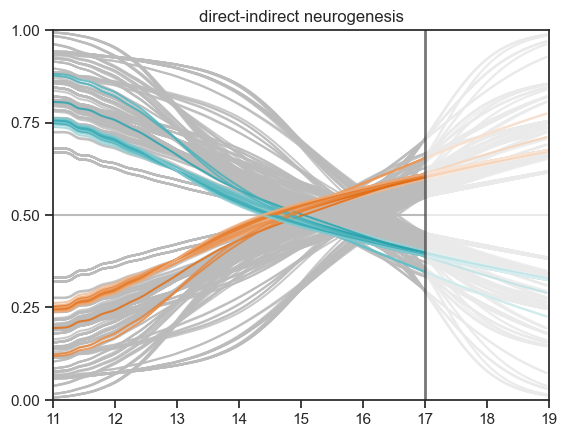

In [22]:
a_color = '#23a3ae'
b_color = '#e46b0f'

starting_c = 125
color_def = 300


a_colors_l = sns.light_palette(a_color, n_colors = color_def)
a_colors_d = sns.dark_palette(a_color, n_colors = color_def, reverse=True)

a_colors = a_colors_l + a_colors_d
a_colors = a_colors[starting_c:starting_c+n_sim]
a_colors = np.array(a_colors)

b_colors_l = sns.light_palette(b_color, n_colors = color_def)
b_colors_d = sns.dark_palette(b_color, n_colors = color_def, reverse=True)

b_colors = b_colors_l + b_colors_d
b_colors = b_colors[starting_c:starting_c+n_sim]
b_colors = np.array(b_colors)


a_colors = a_colors[perm]
b_colors = b_colors[perm]

for i, (idx, y) in enumerate(neurogenesis_df.iterrows()):
    if idx in set(subset_df[subset_df['crossing'] <= 15].index):
        c_d = a_colors[i]
        c_i = b_colors[i]
        zorder = 2
    else:
        c_d = c_i = c_light
        zorder = 1

    plt.plot(days, y, color = c_d, alpha = 0.8, zorder = zorder)
    plt.plot(days, 1-y, color = c_i, alpha = 0.8, zorder = zorder)

plt.title('direct-indirect neurogenesis')

plt.hlines(0.5, xmin=11, xmax=19, color = "#bbbbbb", zorder=1)

plt.gca().add_patch(plt.Rectangle((17, -0.1),
                                  2.2, 1.2,
                                  facecolor="#ffffff",
                                  alpha=0.7,
                                  edgecolor="#3d3d3d",
                                  linewidth=2,
                                  zorder = 2))

plt.yticks(np.arange(0,1.25,0.25))

# plt.grid()
plt.xlim([11,19])
plt.ylim([0,1])


In [23]:
print(len(subset_df[subset_df['crossing'] <= 15]))

19


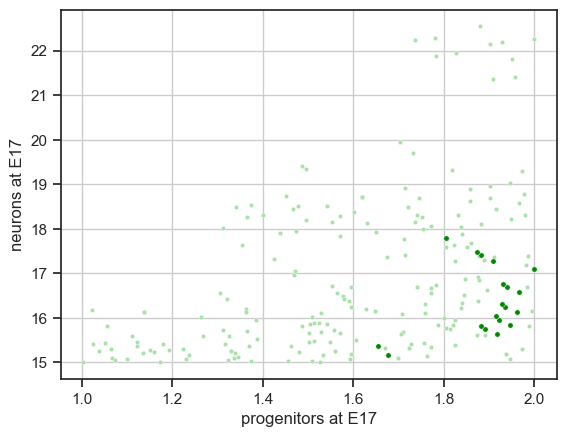

In [24]:
sns.scatterplot(data = subset_df, x = 'prog_17', y = 'neur_17', s = 10, color = color_200_not15)

sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'prog_17', y = 'neur_17', s = 15, color = color_200_15)

plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')

plt.grid()

## checking 3 examples

In [25]:
example1 = subset_df[(subset_df['crossing'] <= 15) & (subset_df['neur_17'] < 15.2)]

example1

,k_A_N,x0_A_N,start_A_N,end_A_N,k_B_N,x0_B_N,start_B_N,end_B_N,a_prog_17,b_prog_17,prog_17,a_neur_17,b_neur_17,neur_17,perc_D_11,perc_D_17,crossing
11846,1.0,2.0,0.5,0.3,1.5,2.0,0.4,1.0,1.111534,0.564033,1.675567,9.240237,5.922732,15.162969,0.875771,0.390026,14.833333


In [26]:
example2 = subset_df[(subset_df['crossing'] <= 15) & (subset_df['prog_17'] > 1.8) & (subset_df['neur_17'] < 15.7)]

example2

,k_A_N,x0_A_N,start_A_N,end_A_N,k_B_N,x0_B_N,start_B_N,end_B_N,a_prog_17,b_prog_17,prog_17,a_neur_17,b_neur_17,neur_17,perc_D_11,perc_D_17,crossing
8158,0.5,6.0,0.4,0.1,1.0,2.0,0.8,1.0,1.271263,0.645085,1.916348,8.713246,6.912724,15.62597,0.750582,0.341706,14.791667


In [27]:
example3 = subset_df[(subset_df['crossing'] <= 15) & (subset_df['neur_17'] > 17.6)]

example3

,k_A_N,x0_A_N,start_A_N,end_A_N,k_B_N,x0_B_N,start_B_N,end_B_N,a_prog_17,b_prog_17,prog_17,a_neur_17,b_neur_17,neur_17,perc_D_11,perc_D_17,crossing
8265,0.5,6.0,0.4,0.2,2.0,2.0,0.6,1.0,1.196892,0.607347,1.804239,10.416811,7.368187,17.784998,0.805321,0.384901,15.0


In [28]:
examples_df = pd.concat([example1, example2, example3], ignore_index=True)
examples_df['name'] = ['example1', 'example2', 'example3']


In [29]:
color_examples = '#ff8A14'

(14.8, 23.0)

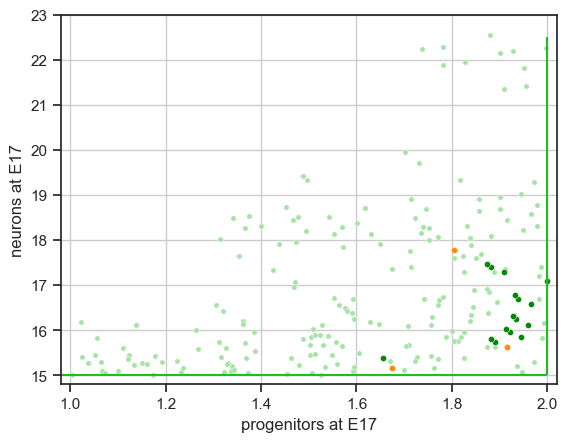

In [30]:
# sns.scatterplot(data = df, x = 'prog_17', y = 'neur_17', s = 15, color = 'black')

sns.scatterplot(data = subset_df, x = 'prog_17', y = 'neur_17', s = 15, color = color_200_not15)

sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'prog_17', y = 'neur_17', s = 20, color = color_200_15)

sns.scatterplot(data = examples_df, x = 'prog_17', y = 'neur_17', s = 20, color = color_examples)

plt.vlines(x = prog_th, ymin = 15, ymax = 22.5, color = color_200, zorder=1)
plt.hlines(y = neur_th, xmin = 0.98, xmax = 2, color = color_200, zorder=1)

plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')

plt.grid()
plt.xlim(0.98, 2.02)
plt.ylim(14.8, 23)


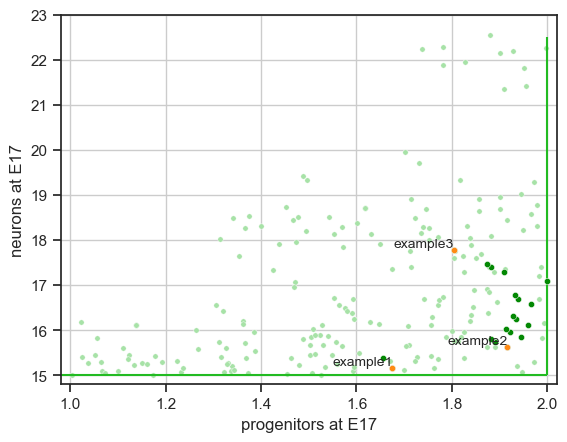

In [31]:
# sns.scatterplot(data = df, x = 'prog_17', y = 'neur_17', s = 15, color = 'black')

sns.scatterplot(data = subset_df, x = 'prog_17', y = 'neur_17', s = 15, color = color_200_not15)

plt.vlines(x = prog_th, ymin = 15, ymax = 22.5, color = color_200, zorder=1)
plt.hlines(y = neur_th, xmin = 0.98, xmax = 2, color = color_200, zorder=1)

sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'prog_17', y = 'neur_17', s = 20, color = color_200_15)

sns.scatterplot(data = examples_df, x = 'prog_17', y = 'neur_17', s = 20, color = color_examples)
plt.xlabel('progenitors at E17')
plt.ylabel('neurons at E17')

plt.grid()
plt.xlim(0.98, 2.02)
plt.ylim(14.8, 23)

for xi, yi, label in zip(examples_df['prog_17'], examples_df['neur_17'], examples_df['name']):
    plt.text(xi, yi, label, fontsize=10, ha='right', va='bottom')


### example 1

In [32]:
example1.iloc[0,:8]

k_A_N        1.0
x0_A_N       2.0
start_A_N    0.5
end_A_N      0.3
k_B_N        1.5
x0_B_N       2.0
start_B_N    0.4
end_B_N      1.0
Name: 11846, dtype: float64

In [33]:
example1 = pd.DataFrame({'k_A_N': [1.0],
                        'x0_A_N': [2.0],
                        'start_A_N': [0.5],
                        'end_A_N': [0.3],
                        'k_B_N': [1.5],
                        'x0_B_N': [2.0],
                        'start_B_N': [0.4],
                        'end_B_N': [1.0]})

apical setup:   0%|          | 0/192 [00:00<?, ?it/s]

calculation: 100%|██████████| 192/192 [00:13<00:00, 13.79it/s]


192


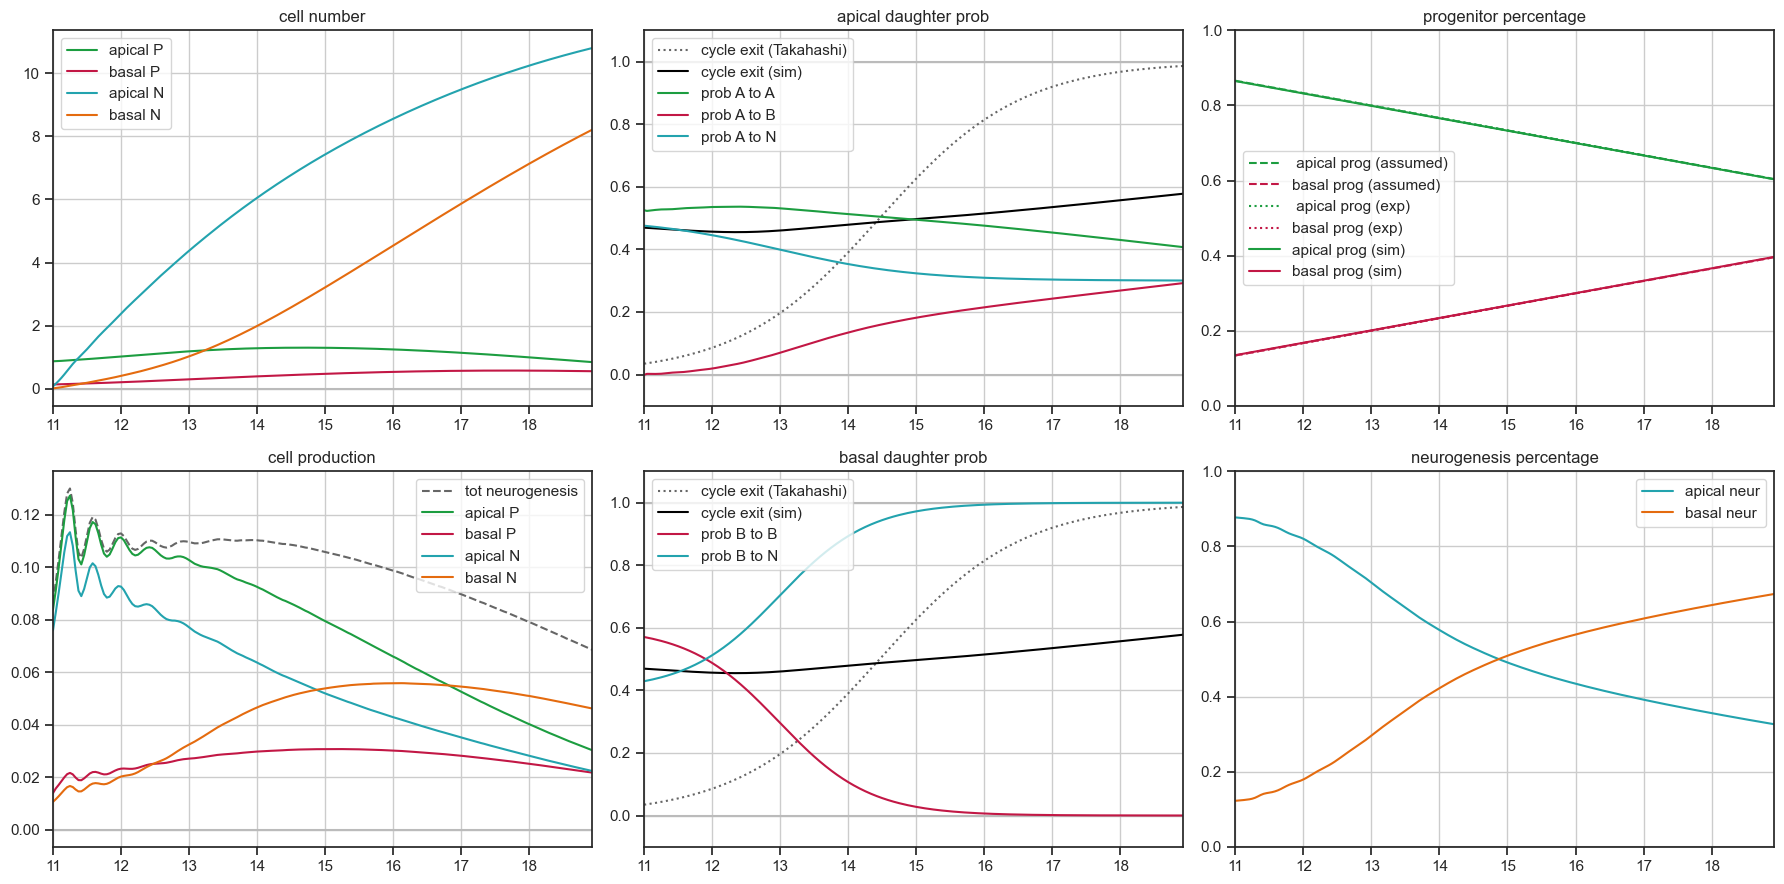

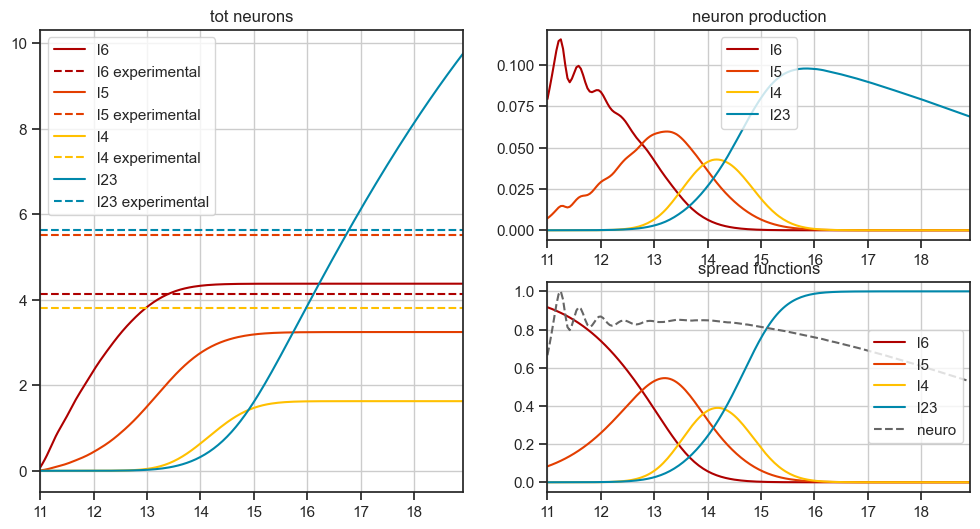

In [34]:
pA_to_N_fc = create_sigmoid(*example1.iloc[0,:4])
pB_to_N_fc = create_sigmoid(*example1.iloc[0,4:8])

a0_perc = 0.866
example1_sim = CellSimulation(
            n_aP0=a0_perc, n_bP0=1-a0_perc,

            layers_dist=layers_gaus_coef,
            layers_perc=layers_density,

            min_per_frame=60,

            pA_to_N_fc = pA_to_N_fc,
            perc_A_fc = lambda x: -0.0330568898* x + 0.8658511766,

            pB_to_N_fc = pB_to_N_fc,
            )

example1_sim.run()
example1_sim.plot()
example1_sim.plot_layers()

### example 2

In [35]:
example2.iloc[0,:8]

k_A_N        0.5
x0_A_N       6.0
start_A_N    0.4
end_A_N      0.1
k_B_N        1.0
x0_B_N       2.0
start_B_N    0.8
end_B_N      1.0
Name: 8158, dtype: float64

In [36]:
example2 = pd.DataFrame({'k_A_N': [0.5],
                        'x0_A_N': [6.0],
                        'start_A_N': [0.4],
                        'end_A_N': [0.1],
                        'k_B_N': [1.0],
                        'x0_B_N': [2.0],
                        'start_B_N': [0.8],
                        'end_B_N': [1.0]})

calculation: 100%|██████████| 192/192 [00:13<00:00, 14.05it/s]


192


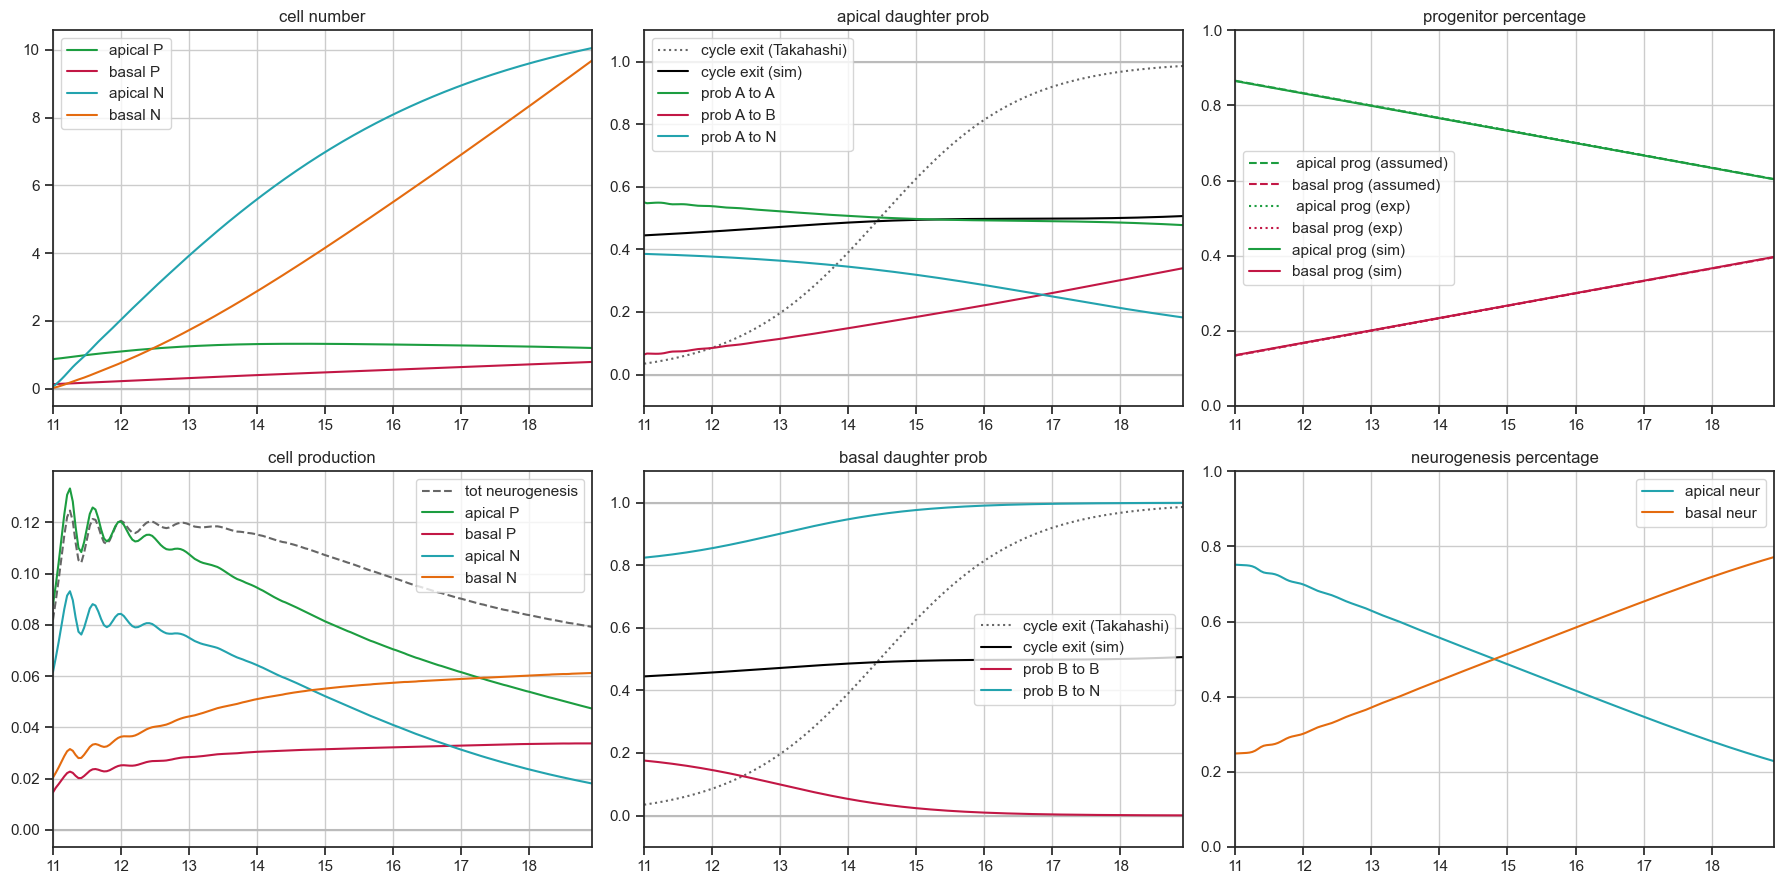

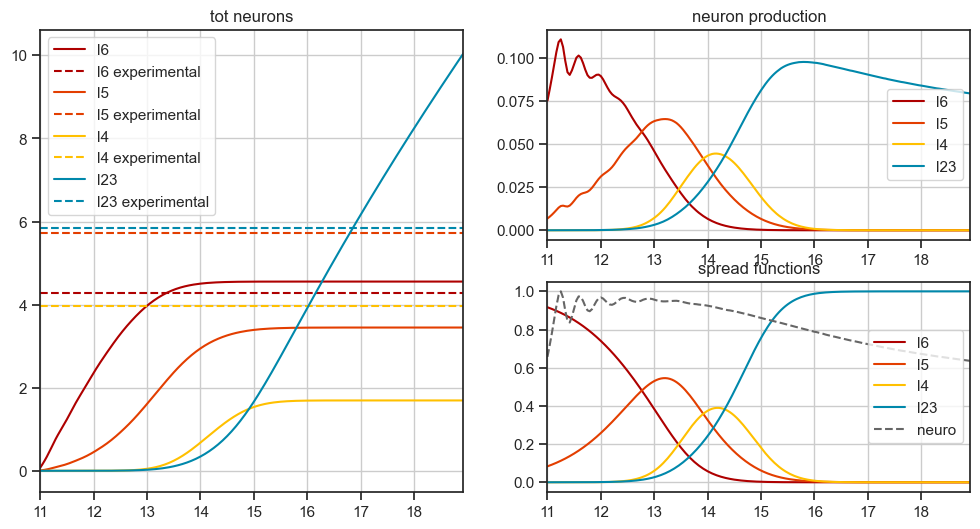

In [37]:
pA_to_N_fc = create_sigmoid(*example2.iloc[0,:4])
pB_to_N_fc = create_sigmoid(*example2.iloc[0,4:8])

a0_perc = 0.866
example2_sim = CellSimulation(
            n_aP0=a0_perc, n_bP0=1-a0_perc,

            layers_dist=layers_gaus_coef,
            layers_perc=layers_density,

            min_per_frame=60,

            pA_to_N_fc = pA_to_N_fc,
            perc_A_fc = lambda x: -0.0330568898* x + 0.8658511766,

            pB_to_N_fc = pB_to_N_fc,
            )

example2_sim.run()
example2_sim.plot()
example2_sim.plot_layers()

### example 3

In [38]:
example3.iloc[0,:8]

k_A_N        0.5
x0_A_N       6.0
start_A_N    0.4
end_A_N      0.2
k_B_N        2.0
x0_B_N       2.0
start_B_N    0.6
end_B_N      1.0
Name: 8265, dtype: float64

In [39]:
example3 = pd.DataFrame({'k_A_N': [0.5],
                        'x0_A_N': [6.0],
                        'start_A_N': [0.4],
                        'end_A_N': [0.2],
                        'k_B_N': [2.0],
                        'x0_B_N': [2.0],
                        'start_B_N': [0.6],
                        'end_B_N': [1.0]})

calculation: 100%|██████████| 192/192 [00:13<00:00, 14.09it/s]


192


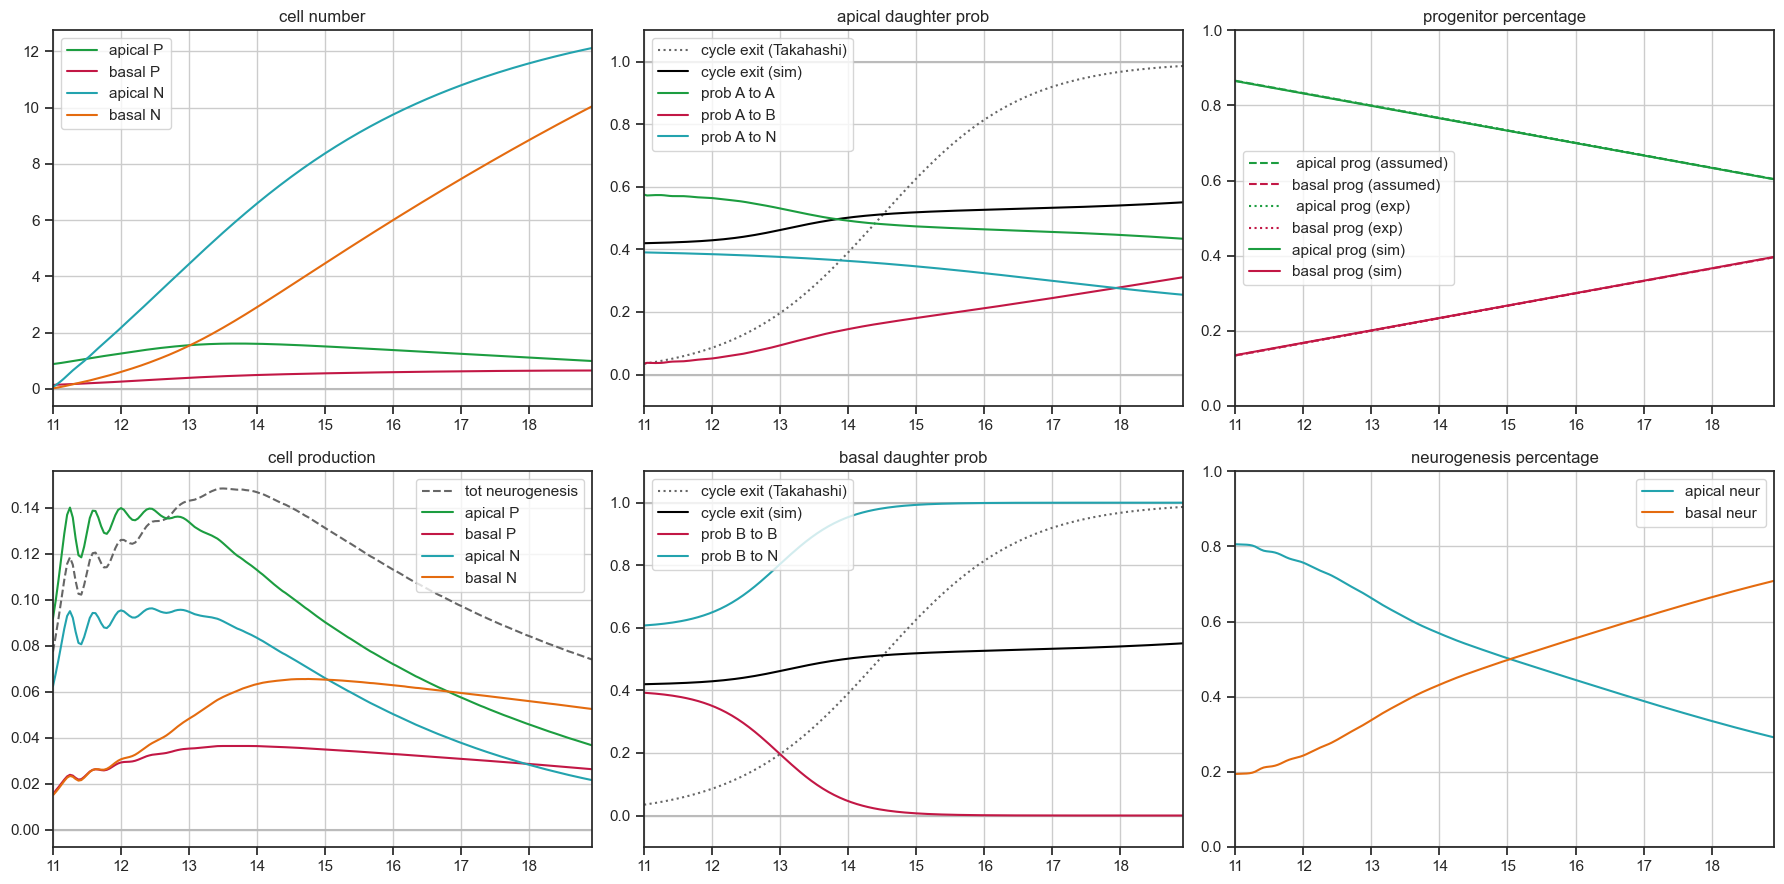

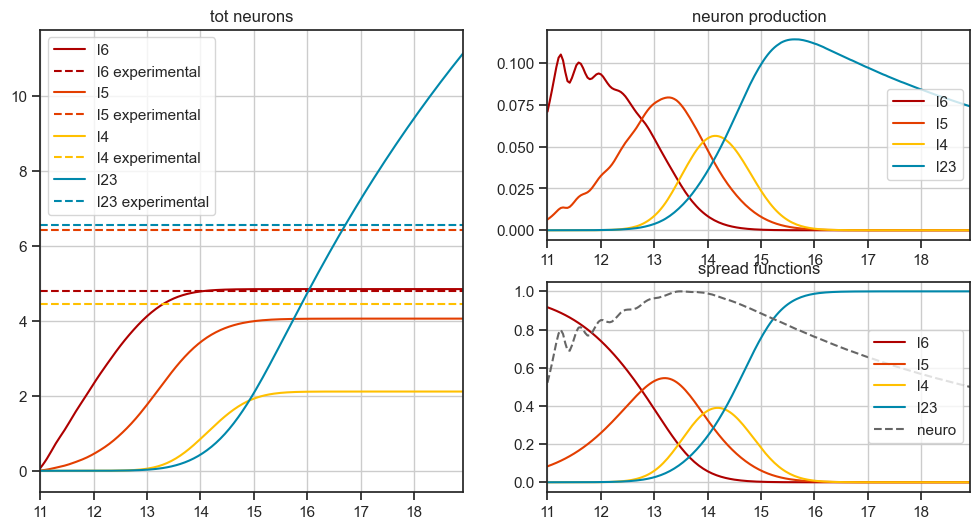

In [40]:
pA_to_N_fc = create_sigmoid(*example3.iloc[0,:4])
pB_to_N_fc = create_sigmoid(*example3.iloc[0,4:8])

a0_perc = 0.866
example3_sim = CellSimulation(
            n_aP0=a0_perc, n_bP0=1-a0_perc,

            layers_dist=layers_gaus_coef,
            layers_perc=layers_density,

            min_per_frame=60,

            pA_to_N_fc = pA_to_N_fc,
            perc_A_fc = lambda x: -0.0330568898* x + 0.8658511766,

            pB_to_N_fc = pB_to_N_fc,
            )

example3_sim.run()
example3_sim.plot()
example3_sim.plot_layers()

In [41]:
sim_names = ['example1', 'example2', 'example3']

sims = [example1_sim, example2_sim, example3_sim]

ex_metrics_dicts = []
tables_dict = {}

for i, sim in enumerate(sims):
    ex_metrics_dict = sim.get_metrics()
    ex_metrics_dict['source'] = sim_names[i]
    ex_metrics_dicts.append(ex_metrics_dict)
    
    tables_dict[sim_names[i]] = sim.get_tables()

ex_metrics_df = pd.DataFrame(ex_metrics_dicts)

In [42]:
layers_n_df = pd.DataFrame()

layers_n_df = ex_metrics_df[[col for col in ex_metrics_df.columns if col.endswith('_n')]]
layers_n_df.columns = layers_n_df.columns.str.slice(stop=-2)

layers_n_df = layers_n_df.set_index(ex_metrics_df['source'])

layers_n_df

,l6,l5,l4,l23
source,,,,
example1,4.374479,3.244300,1.627997,9.819382
example2,4.554883,3.448751,1.693631,10.109506
example3,4.849584,4.061394,2.115327,11.208947


In [43]:
layers_p_df = pd.DataFrame()

layers_p_df = ex_metrics_df[[col for col in ex_metrics_df.columns if col.endswith('_p')]]
layers_p_df.columns = layers_p_df.columns.str.slice(stop=-2)

layers_p_df = layers_p_df.set_index(ex_metrics_df['source'])

layers_p_df

,l6,l5,l4,l23
source,,,,
example1,0.229437,0.170160,0.085387,0.515016
example2,0.229966,0.174120,0.085508,0.510407
example3,0.218103,0.182656,0.095134,0.504107


Text(0.5, 1.0, 'Layer absolute numbers')

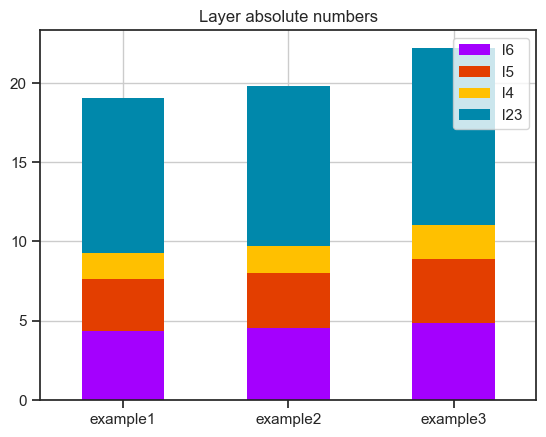

In [44]:
fig, ax = plt.subplots()

layers_n_df.plot(kind='bar', stacked=True, color = colors, edgecolor='none', linewidth=0, ax=ax)
ax.set_xticklabels(layers_n_df.index, rotation = 0)
ax.grid()
ax.set_axisbelow(True)
ax.set_xlabel('')
ax.set_title('Layer absolute numbers')


In [45]:
layers_density = pd.read_csv('layers_percent.csv')
# i want to sum starting from l6
layers_perc = layers_density['percent'].values[::-1]

print(layers_density)
print()
print(layers_perc)

layers_perc = np.cumsum(layers_perc)
print(layers_perc)

  layer   percent
0   l23  0.295036
1    l4  0.199940
2    l5  0.288617
3    l6  0.216406

[0.21640608 0.28861736 0.19994028 0.29503627]
[0.21640608 0.50502345 0.70496373 1.        ]


Text(0.5, 1.0, 'layer percentages')

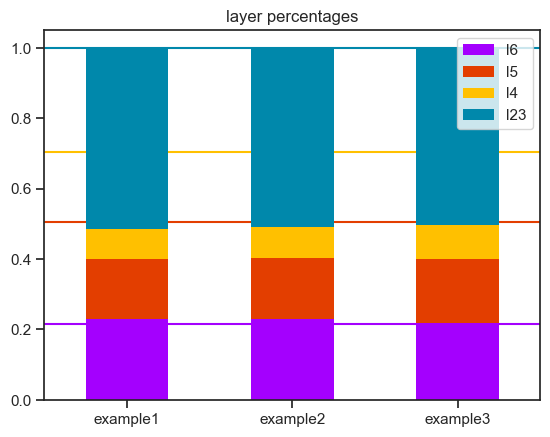

In [46]:
fig, ax = plt.subplots()

layers_p_df.plot(kind='bar', stacked=True, color=colors, ax=ax, edgecolor='none', linewidth=0)
ax.set_xticklabels(layers_p_df.index, rotation = 0)

for i in range(4):
    current_layer =  layers_perc[i]
    ax.hlines(y = current_layer, xmin = -5, xmax = len(layers_p_df), color=colors[i], zorder=0)

ax.set_xlabel('')
ax.set_title('layer percentages')

In [47]:
layers_n_df = pd.DataFrame()

layers_n_df = metric_df[[col for col in metric_df.columns if col.endswith('_n')]]
layers_n_df.columns = layers_n_df.columns.str.slice(stop=-2)
layers_n_df

,l6,l5,l4,l23
1805,4.793269,3.801870,1.867357,6.096539
1811,4.793269,3.801870,1.867357,6.096539
1817,4.793269,3.801870,1.867357,6.096539
1823,4.793269,3.801870,1.867357,6.096539
1829,4.793269,3.801870,1.867357,6.096539
...,...,...,...,...
35845,4.425905,3.375450,1.802785,6.811318
35899,4.427529,3.360092,1.762234,6.478789
35917,4.425992,3.376095,1.804053,6.862292
35971,4.427612,3.360695,1.763415,6.526572


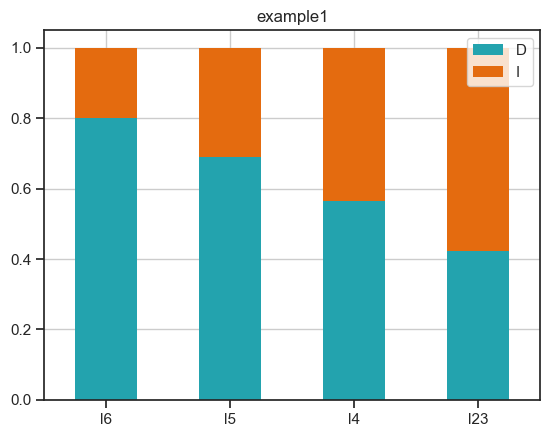

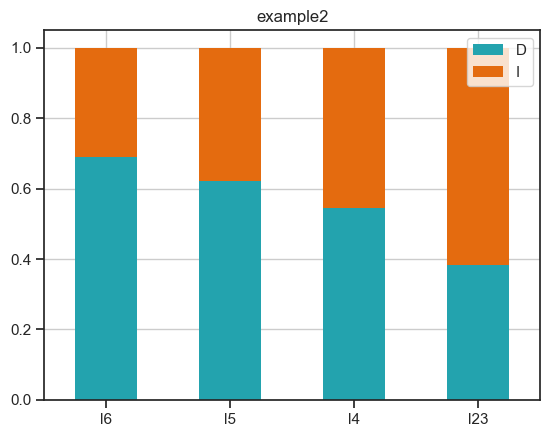

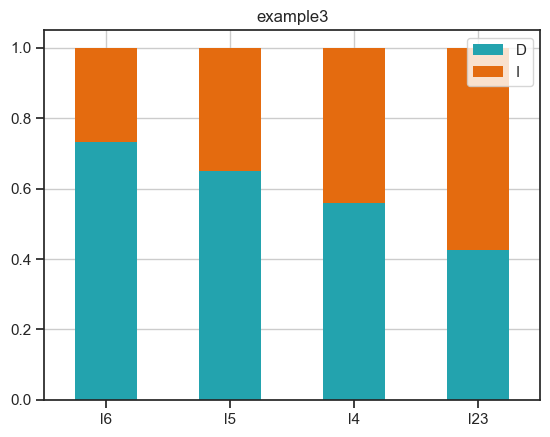

In [48]:
layer_names = list(layer_colors.keys())

for sim_name in sim_names:

    layers_np = tables_dict[sim_name]['layers']

    layers_aggregate = np.sum(layers_np, axis = 2)

    perc_dict = {}

    for i in range(layers_aggregate.shape[1]):
        l = layers_aggregate[:,i]
        
        perc_dict[layer_names[i]] = float(l[0] / np.sum(l))

    perc_df = pd.DataFrame.from_dict(perc_dict, orient='index', columns=['D'])
    perc_df['I'] = 1 - perc_df['D']


    # print(perc_df)
    fig, ax = plt.subplots()

    ax = perc_df.plot(kind='bar', stacked=True, color = neuro_colors[2:4], edgecolor='none', linewidth=0, ax=ax)
    ax.set_xticklabels(perc_df.index, rotation = 0)
    ax.grid()
    ax.set_axisbelow(True)
    ax.set_xlabel('')
    ax.set_title(sim_name)
    

In [49]:
max_prog = np.zeros([2, len(sim_names)])
tot_neur = np.zeros([2, len(sim_names)])
end_prog = np.zeros([2, len(sim_names)])

for i, s in enumerate(sim_names):
    prog_n = tables_dict[s]['n_cells'][:2]
    max_prog[0, i] = np.max(prog_n[0])
    max_prog[1, i] = np.max(prog_n[1])

    layers_np = tables_dict[s]['n_cells']
    at = np.where(days >= 17)[0][0]

    tot_neur[:,i] = tables_dict[s]['n_cells'][2:,at]
    end_prog[:,i] = prog_n[:,at]


# print(tot_neur)
tot_n = np.sum(tot_neur, axis = 0)

print('total N (apical - basal)')
print(tot_neur)
print(tot_n)
print()
print('apical N perc')
print(tot_neur[0] / (tot_neur[0] + tot_neur[1]))
print()

print()
print('max prog')
print(max_prog)

print()
print('prog at e17')
print(end_prog)

print()
print('ratio')
print(tot_n/max_prog[0])
# print(tot_n / max_prog)


total N (apical - basal)
[[ 9.48790755  8.94888808 10.7982324 ]
 [ 5.86654214  6.90882822  7.46794583]]
[15.35444969 15.85771629 18.26617823]

apical N perc
[0.6179256  0.56432389 0.59115992]


max prog
[[1.30183685 1.32709212 1.60749655]
 [0.5762885  0.79365726 0.64889433]]

prog at e17
[[1.13964121 1.27765215 1.2419747 ]
 [0.56942457 0.63838207 0.62055575]]

ratio
[11.79445004 11.94922042 11.36312126]


<Axes: >

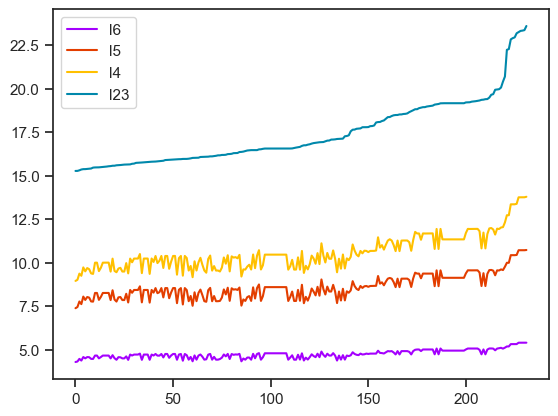

In [50]:
layers_n_df_sorted = layers_n_df.copy()
layers_n_df_sorted['total'] = layers_n_df[['l23', 'l4', 'l5', 'l6']].sum(axis=1)

layers_n_df_sorted = layers_n_df_sorted.sort_values(by='total').reset_index(drop=True).drop(columns='total')

layers_n_df_sorted.plot(kind='line', stacked=True, color = colors)

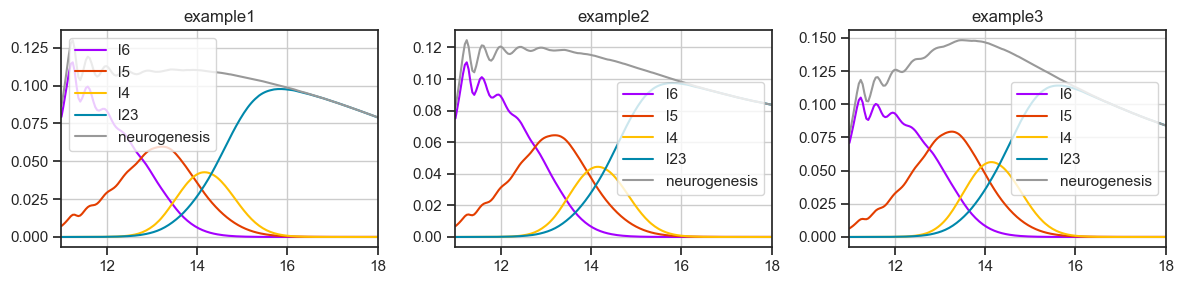

In [51]:
cols = 3

fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 3))

axes = axes.flatten()

k = 3

for i, s in enumerate(sim_names):
    ax = axes[i]

    x = days

    layers_n = tables_dict[s]['layers']

    layers_sum = np.sum(layers_n, axis = 0)


    tot_neurogenesis = tables_dict[s]['new_cells'][2,:] + tables_dict[s]['new_cells'][3,:]


    for i, l in enumerate(layers):
        current_layer = l
        current_color = layer_colors[l]


        ax.plot(x, layers_sum[i], label=current_layer, color=current_color)


    ax.plot(x, tot_neurogenesis, label='neurogenesis', color='#999999')

    ax.set_title(f'{s}')

    ax.set_xlim([11,18])

    ax.legend()
    ax.grid()

# hide any unused subplots if k < rows*cols
for j in range(k, cols):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

In [52]:
metrics_dicts = []
tables_dict = {}

for i, sim in enumerate(sims):
    metrics_dict = sim.get_metrics()
    metrics_dict['source'] = sim_names[i]
    metrics_dicts.append(metrics_dict)
    
    tables_dict[sim_names[i]] = sim.get_tables()

metrics_df = pd.DataFrame(metrics_dicts)

In [53]:
metrics_source = metrics_df['source'].values

# let's get the end point (neurons > 99.5%)
end_points_values = metrics_df['end_point'].values

end_points_dict = dict(zip(metrics_source, end_points_values))

# let's get the end point (neurons < 0.5%)
start_points_values = metrics_df['start_point'].values

start_points_dict = dict(zip(metrics_source, start_points_values))

11.041666666666666 18.916666666666668
11.041666666666666 18.916666666666668
11.041666666666666 18.916666666666668


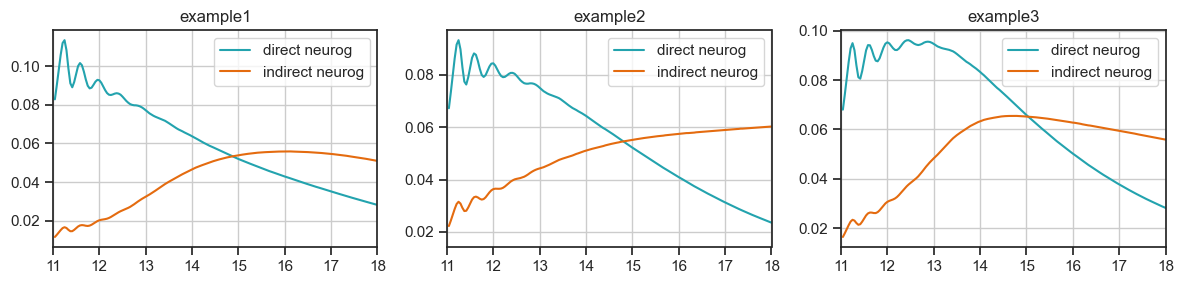

In [54]:
k = 3

cols = 3

fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 3))

axes = axes.flatten()

for i, s in enumerate(sim_names):
    ax = axes[i]

    x = days

    neurogenesis_n = tables_dict[s]['new_cells'][2:]

    # perc_a
    y_a = neurogenesis_n[0]
    y_b = neurogenesis_n[1]


    current_start = start_points_dict[s]
    current_end = end_points_dict[s]

    print(current_start, current_end)

    y_a[x<current_start] = None
    y_a[x>current_end] = None

    y_b[x<current_start] = None
    y_b[x>current_end] = None

    ax.plot(x, y_a, color = neuro_colors_dict['apical N'], label = 'direct neurog')
    ax.plot(x, y_b, color = neuro_colors_dict['basal N'], label = 'indirect neurog')
    ax.set_title(f'{s}')

    ax.set_xlim([11,18])

    ax.legend()
    ax.grid()

# hide any unused subplots if k < rows*cols
for j in range(k, cols):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

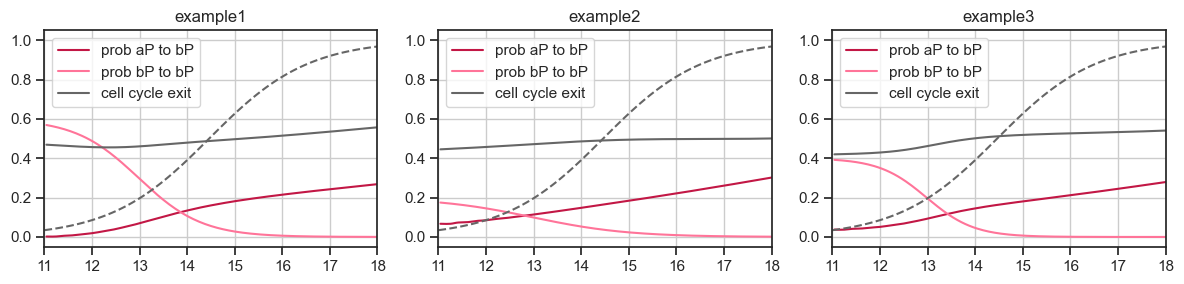

In [55]:
k = len(sims)

default_pE = lambda x: 1/(1 + np.exp(-0.9620962961790901*(x-3.4620613854762183)))
x_0 = np.linspace(0,7, 100)

cols = 3

fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 3))

axes = axes.flatten()

for i, s in enumerate(sim_names):
    ax = axes[i]

    x = days

    y_pE = tables_dict[s]['probs'][5]
    y_pA_to_B = tables_dict[s]['probs'][1]
    y_pB_to_B = tables_dict[s]['probs'][3]


    current_start = start_points_dict[s]
    current_end = end_points_dict[s]

    y_pE[x<current_start] = None
    y_pE[x>current_end] = None

    y_pA_to_B[x<current_start] = None
    y_pA_to_B[x>current_end] = None

    y_pB_to_B[x<current_start] = None
    y_pB_to_B[x>current_end] = None


    ax.plot(x, y_pA_to_B, color = neuro_colors_dict['basal P'], label = 'prob aP to bP')
    ax.plot(x, y_pB_to_B, color = neuro_colors[5], label = 'prob bP to bP')
    ax.plot(x, y_pE, color = neuro_colors[4], label = 'cell cycle exit')
    
    ax.plot(x_0+11, default_pE(x_0), color = neuro_colors[4], linestyle='--')

    ax.set_title(f'{s}')

    ax.set_xlim([11,18])
    ax.set_ylim([-0.05,1.05])

    ax.legend()
    ax.grid()

# hide any unused subplots if k < rows*cols
for j in range(k, cols):
    fig.delaxes(axes[j])

plt.tight_layout()

plt.show()

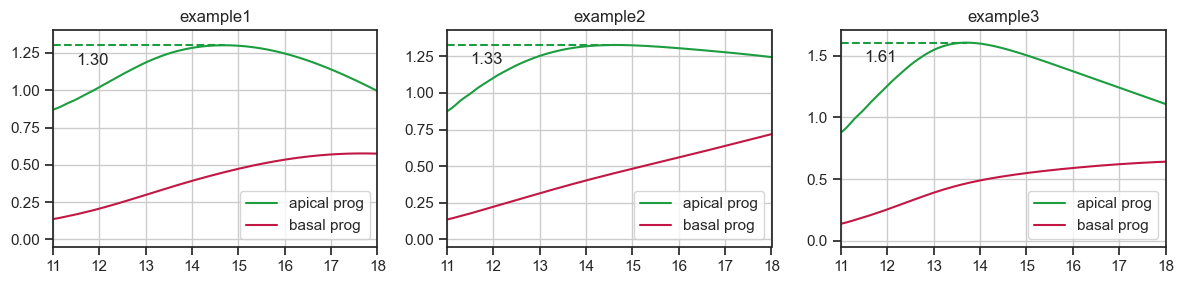

In [56]:
k = 3

cols = 3

fig, axes = plt.subplots(1, cols, figsize=(4 * cols, 3))

axes = axes.flatten()

for i, s in enumerate(sim_names):
    ax = axes[i]

    x = days

    prog_n = tables_dict[s]['n_cells'][:2]

    # perc_a
    y_a = prog_n[0]
    y_b = prog_n[1]


    current_start = start_points_dict[s]
    current_end = end_points_dict[s]

    y[x<current_start] = None
    y[x>current_end] = None

    ax.plot(x, y_a, color = neuro_colors_dict['apical P'], label = 'apical prog')
    ax.hlines(y = np.max(y_a), xmin = 11, xmax = x[np.argmax(y_a)], color = neuro_colors_dict['apical P'], linestyle = '--')
    ax.text(x = 11.5, y = 0.9 * np.max(y_a), s = f'{np.max(y_a):.2f}')
    ax.plot(x, y_b, color = neuro_colors_dict['basal P'], label = 'basal prog')
    ax.set_title(f'{s}')

    ax.set_xlim([11,18])
    ax.set_ylim([-0.05,  np.max(y_a) + 0.1])

    ax.legend()
    ax.grid()

# hide any unused subplots if k < rows*cols
for j in range(k, cols):
    fig.delaxes(axes[j])

plt.tight_layout()


plt.show()

In [57]:
originals_df = pd.DataFrame({'a_neur_17': [113.16023563,  18.07161169,  22.49752888],
                 'b_neur_17': [100.03430939,  10.60860189,  14.97018539]})
originals_df['name'] = ['Raw', 'D_I', 'I_D']

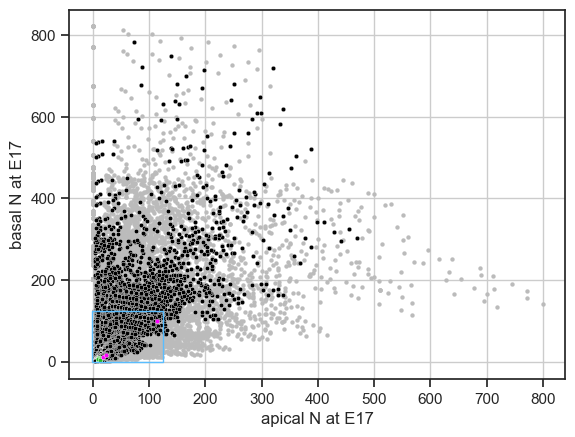

In [58]:
sns.scatterplot(data = df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = c_light, linewidth=0)
sns.scatterplot(data = df_D_I, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'black')
sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = color_200)
sns.scatterplot(data = originals_df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'magenta')
# plt.grid()
plt.xlabel('apical N at E17')
plt.ylabel('basal N at E17')

plt.grid()
plt.gca().add_patch(plt.Rectangle((-2, -2), 127, 127, fill=False, color="#59bdff"))

In [59]:
color_rect = "#2d87c4"

In [60]:
Path = mpath.Path
verts = [
    (0, 20),  # move to
    (0, 40),  # line to
    (40, 0),  # line to
    (20, 0),  # line to
    (0, 20)   # close path
]

codes = [Path.MOVETO, Path.LINETO, Path.LINETO, Path.LINETO, Path.CLOSEPOLY]



(-2.0, 125.0)

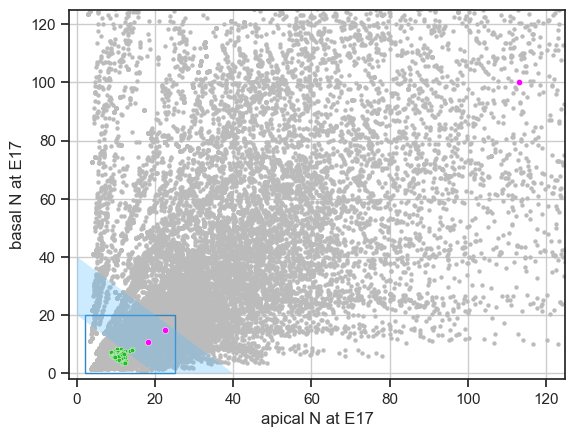

In [61]:
sns.scatterplot(data = df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = c_light, linewidth=0)

# sns.scatterplot(data = df_D_I, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'black')

sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = color_200, zorder=3)

# sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 15, color = color_200_not15)
# sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200_15)
# sns.scatterplot(data = examples_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_examples)

sns.scatterplot(data = originals_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = 'magenta', zorder=3)


plt.gca().add_patch(plt.Rectangle((2, 0), 23, 20, fill=False, color=color_rect))

path = mpath.Path(verts, codes)
polygon = mpatches.PathPatch(
    path,
    facecolor="#59bdff",
    edgecolor='none',
    linewidth=2,
    alpha=0.3,
    zorder=2
)
plt.gca().add_patch(polygon)

plt.grid()
plt.xlabel('apical N at E17')
plt.ylabel('basal N at E17')

plt.xlim([-2,125])
plt.ylim([-2,125])

(-2.0, 125.0)

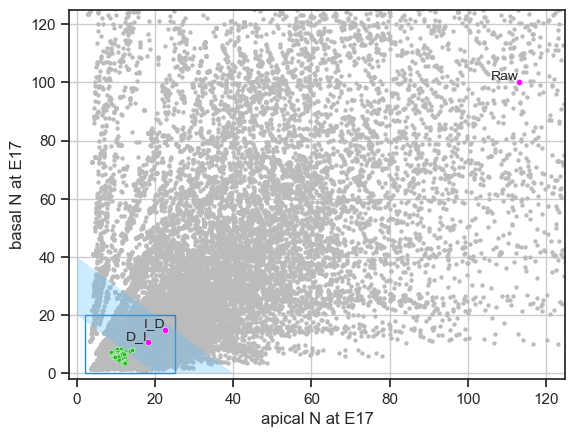

In [62]:
sns.scatterplot(data = df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = c_light, linewidth=0)

# sns.scatterplot(data = df_D_I, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'black')

sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = color_200, zorder=3)

# sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 15, color = color_200_not15)
# sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200_15)
# sns.scatterplot(data = examples_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_examples)

sns.scatterplot(data = originals_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = 'magenta', zorder=3)

for xi, yi, label in zip(originals_df['a_neur_17'], originals_df['b_neur_17'], originals_df['name']):
    plt.text(xi, yi, label, fontsize=10, ha='right', va='bottom', zorder=3)


plt.gca().add_patch(plt.Rectangle((2, 0), 23, 20, fill=False, color=color_rect))

path = mpath.Path(verts, codes)
polygon = mpatches.PathPatch(
    path,
    facecolor="#59bdff",
    edgecolor='none',
    linewidth=2,
    alpha=0.3,
    zorder=2
)
plt.gca().add_patch(polygon)

plt.grid()
plt.xlabel('apical N at E17')
plt.ylabel('basal N at E17')

plt.xlim([-2,125])
plt.ylim([-2,125])

In [63]:
color_200_not15_darker = "#7ff17f"

(0.0, 20.0)

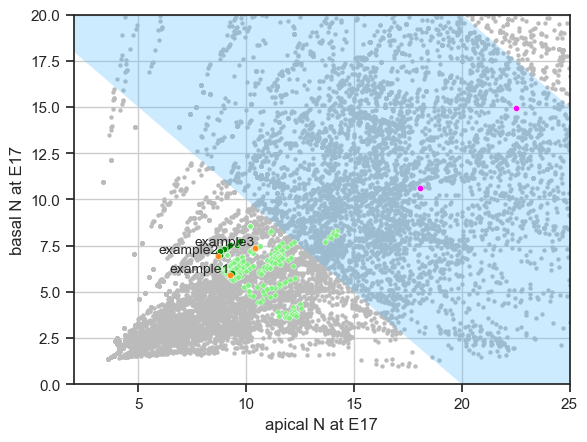

In [64]:
sns.scatterplot(data = df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = c_light, linewidth=0)

# sns.scatterplot(data = df_D_I, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'black')

# sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200, zorder=3)

# light green
sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 15, color = color_200_not15_darker, zorder=3)

# dark green
sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200_15, zorder=3)

# three sim in magenta
sns.scatterplot(data = originals_df[originals_df['a_neur_17'] < 30], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = 'magenta', zorder=3)

# three examples
sns.scatterplot(data = examples_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_examples, zorder=3)


for xi, yi, label in zip(examples_df['a_neur_17'], examples_df['b_neur_17'], examples_df['name']):
    plt.text(xi, yi, label, fontsize=10, ha='right', va='bottom')

plt.grid()
plt.xlabel('apical N at E17')
plt.ylabel('basal N at E17')

path = mpath.Path(verts, codes)
polygon = mpatches.PathPatch(
    path,
    facecolor="#59bdff",
    edgecolor='none',
    linewidth=2,
    alpha=0.3,
    zorder=2
)
plt.gca().add_patch(polygon)

plt.xlim([2,25])
plt.ylim([0,20])


(0.0, 20.0)

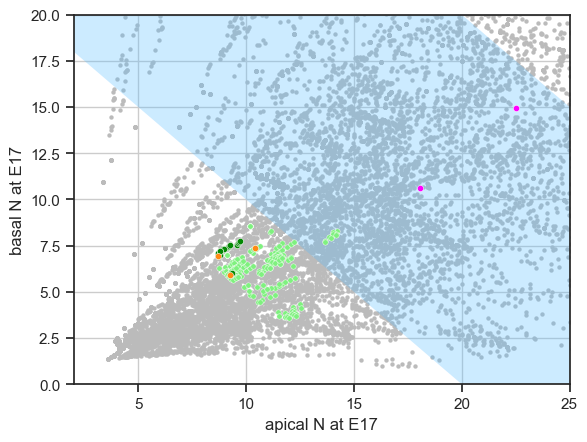

In [65]:
sns.scatterplot(data = df, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = c_light, linewidth=0)

# sns.scatterplot(data = df_D_I, x = 'a_neur_17', y = 'b_neur_17', s = 10, color = 'black')

# sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200, zorder=3)

# light green
sns.scatterplot(data = subset_df, x = 'a_neur_17', y = 'b_neur_17', s = 15, color = color_200_not15_darker, zorder=3)

# dark green
sns.scatterplot(data = subset_df[subset_df['crossing'] <= 15], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_200_15, zorder=3)

# three sim in magenta
sns.scatterplot(data = originals_df[originals_df['a_neur_17'] < 30], x = 'a_neur_17', y = 'b_neur_17', s = 20, color = 'magenta', zorder=3)

# three examples
sns.scatterplot(data = examples_df, x = 'a_neur_17', y = 'b_neur_17', s = 20, color = color_examples, zorder=3)


plt.grid()
plt.xlabel('apical N at E17')
plt.ylabel('basal N at E17')

path = mpath.Path(verts, codes)
polygon = mpatches.PathPatch(
    path,
    facecolor="#59bdff",
    edgecolor='none',
    linewidth=2,
    alpha=0.3,
    zorder=2
)
plt.gca().add_patch(polygon)

plt.xlim([2,25])
plt.ylim([0,20])

In [66]:
print('tested sims: ', df.shape[0])
print('bottom-right quadrant: ', df_D_I.shape[0])
print('high neurons - low prog at e17: ', subset_df.shape[0])
print('crossing before e15: ', subset_df[subset_df['crossing'] <= 15].shape[0])

tested sims:  36288
bottom-right quadrant:  15917
high neurons - low prog at e17:  232
crossing before e15:  19


In [67]:
print(examples_df)



   k_A_N  x0_A_N  start_A_N  end_A_N  k_B_N  x0_B_N  start_B_N  end_B_N  \
0    1.0     2.0        0.5      0.3    1.5     2.0        0.4      1.0   
1    0.5     6.0        0.4      0.1    1.0     2.0        0.8      1.0   
2    0.5     6.0        0.4      0.2    2.0     2.0        0.6      1.0   

   a_prog_17  b_prog_17   prog_17  a_neur_17  b_neur_17    neur_17  perc_D_11  \
0   1.111534   0.564033  1.675567   9.240237   5.922732  15.162969   0.875771   
1   1.271263   0.645085  1.916348   8.713246   6.912724  15.625970   0.750582   
2   1.196892   0.607347  1.804239  10.416811   7.368187  17.784998   0.805321   

   perc_D_17   crossing      name  
0   0.390026  14.833333  example1  
1   0.341706  14.791667  example2  
2   0.384901  15.000000  example3  
